# plotting v3_1 output

In [2]:
import sys
import math
from datetime import datetime

import numpy as np
import matplotlib.pyplot as plt
from netCDF4 import Dataset # !! new - building netcdf
import os # file saving 
import xarray as xr
from pathlib import Path
import importlib.util


In [3]:
save_loc_v3_1 = "./model_output_v3_1/" # location to save output files
save_name = 'ctrl'
ncfile = xr.open_dataset(f"{save_loc_v3_1}{save_name}.nc", decode_times=False)
ncfile_envi = xr.open_dataset(f"{save_loc_v3_1}{save_name}.nc", group="environment", engine="netcdf4",decode_times=False)
ncfile_ice = xr.open_dataset(f"{save_loc_v3_1}{save_name}.nc", group="ice_particles", engine="netcdf4",decode_times=False)
ncfile_splinter = xr.open_dataset(f"{save_loc_v3_1}{save_name}.nc", group="splinter_particles", engine="netcdf4",decode_times=False)

# also pull out the variables put into the namelist file
namelist_file = ncfile.attrs["namelist_file"]
with open(namelist_file, "r") as f:
    namelist_contents = f.read()
namelist = {} ## all the namelist inputs are stored in this dictionary
exec(namelist_contents, {"np": np}, namelist)

## pull out relevent functions
sys.path.append('/home/users/esree/simple-graupel-model/')
# i have moved all the smaller functions to a seperate file - so can be accessed when plotting too
from graupel_model_sub_functions import trev, ptz

/home/users/esree/miniforge3/envs/vs_code_envi/lib/python3.13/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


FileNotFoundError: [Errno 2] No such file or directory: '/home/users/esree/simple-graupel-model/namelist.txt'

In [5]:
zbase = ptz(namelist['pbase']) # height of cloud base (m)
zbase

2951.706425601365

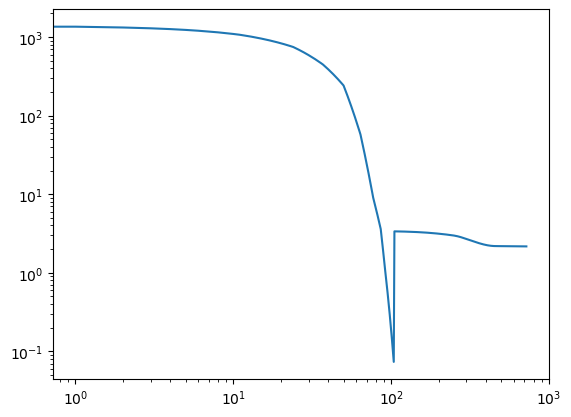

In [3]:
part_0 = ncfile_ice.isel(particle=0)
#part_0
plt.plot(part_0['concentration'])
plt.yscale('log')
plt.xscale('log')

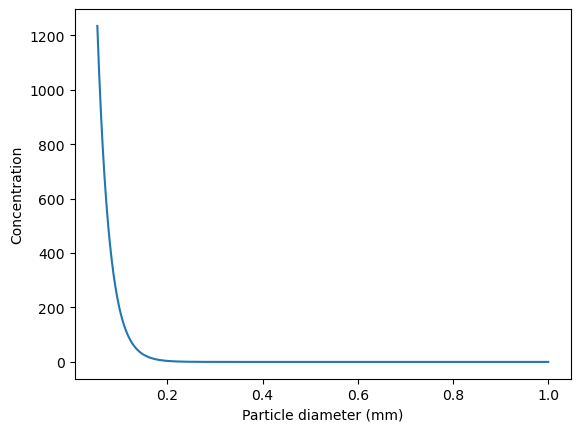

In [4]:
import numpy as np
import matplotlib.pyplot as plt

dmm = np.linspace(0.053, 1.0, 500)  # diameter in mm


conc_n = 10**4 * np.exp(-39.47 * dmm)

plt.plot(dmm, conc_n)

plt.xlabel("Particle diameter (mm)")
plt.ylabel("Concentration")
plt.show()

In [6]:
ncfile

<xarray.Dataset> Size: 9kB
Dimensions:            (time: 721, height: 1500, particle: 20,
                        splinter_particle: 59)
Coordinates:
  * time               (time) float32 3kB 0.0 5.0 10.0 ... 3.595e+03 3.6e+03
  * height             (height) float32 6kB 0.0 10.0 ... 1.498e+04 1.499e+04
  * particle           (particle) int32 80B 0 0 0 0 0 0 0 0 ... 1 1 1 1 1 2 2 2
  * splinter_particle  (splinter_particle) int32 236B 0 1 2 3 4 ... 55 56 57 58
Data variables:
    *empty*
Attributes:
    pyfile_name:    /home/users/esree/simple-graupel-model/graupel_model_new_...
    namelist_file:  /home/users/esree/simple-graupel-model/namelist.txt

Text(0, 0.5, 'altitude (m)')

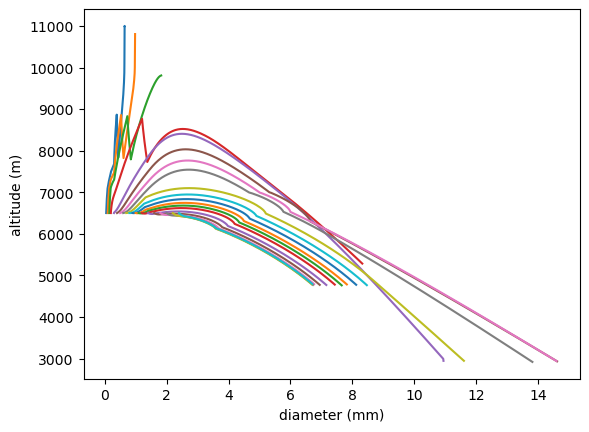

In [15]:
for s in range(ncfile_ice.sizes['particle']):
    p0_ice = ncfile_ice.isel(particle=s)
    #plt.plot(ncfile_v3_1['time'],p0_ice['altitude'])
    #plt.plot(p0_ice['diameter']*1000, p0_ice['altitude'])
    #plt.plot(ncfile['time']/60, p0_ice['diameter']*1000)
    plt.plot(p0_ice['diameter']*1000, p0_ice['altitude'])

plt.xlabel("diameter (mm)")
plt.ylabel("altitude (m)")


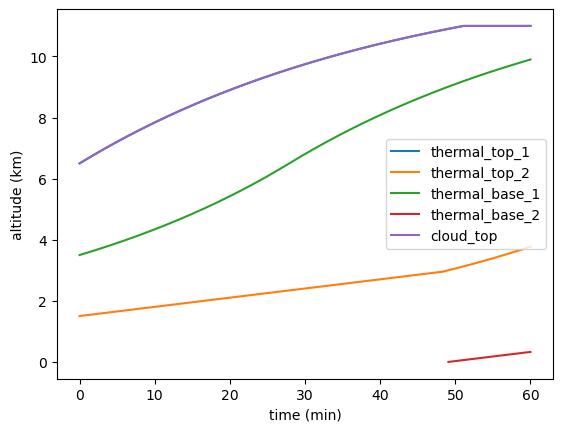

In [ ]:
#plt.plot(ncfile['time']/60, ncfile_envi['thermal_top_1'], label='thermal_top_1')
#plt.plot(ncfile['time']/60, ncfile_envi['thermal_top_2'], label='thermal_top_2')
#plt.plot(ncfile['time']/60, ncfile_envi['thermal_base_1'], label='thermal_base_1')
#plt.plot(ncfile['time']/60, ncfile_envi['thermal_base_2'], label='thermal_base_2')
plt.plot(ncfile['time']/60, ncfile_envi['cloud_top'], label='cloud_top')
plt.plot(ncfile['time']/60, ncfile_envi['cloud_top'], label='cloud_top')

plt.ylabel("altitude (km)")
plt.xlabel("time (min)")
plt.legend()

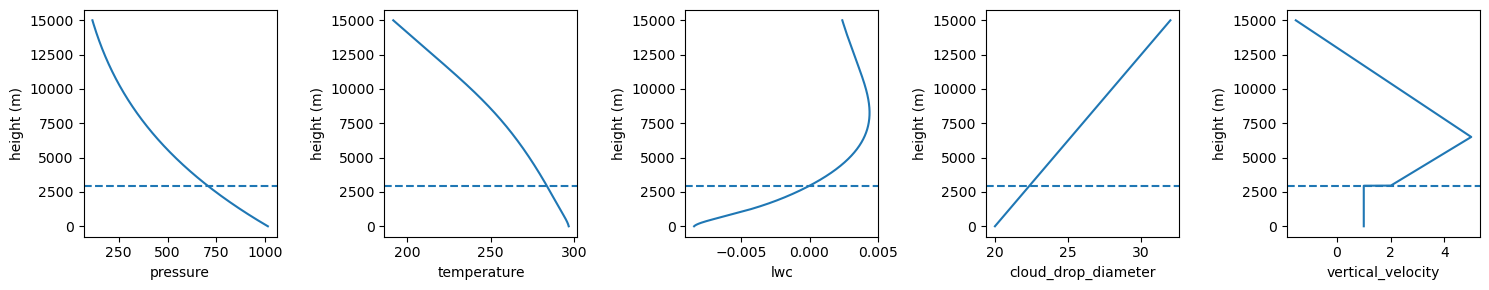

In [7]:
height_vars = ['pressure', 'temperature', 'lwc', 'cloud_drop_diameter', 'vertical_velocity']

fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for i, ax in enumerate(axes):

    ax.plot(ncfile_envi[height_vars[i]], ncfile['height'])

    ax.axhline(
        y=zbase,
        linestyle="--",
        label=f"zbase = {zbase} m"
    )

    ax.set_xlabel(height_vars[i])
    ax.set_ylabel("height (m)")

plt.tight_layout()
plt.show()


In [5]:
import sys
import math
from datetime import datetime

import numpy as np
import matplotlib.pyplot as plt
from netCDF4 import Dataset # !! new - building netcdf
import os # file saving 
import xarray as xr
from pathlib import Path
import importlib.util

save_loc_v3_2 = "./model_output_v3_2/" # location to save output files
save_name = 'blyth_latham'
ncfile = xr.open_dataset(f"{save_loc_v3_2}{save_name}.nc", decode_times=False)
ncfile_envi = xr.open_dataset(f"{save_loc_v3_2}{save_name}.nc", group="environment", engine="netcdf4",decode_times=False)
ncfile_ice = xr.open_dataset(f"{save_loc_v3_2}{save_name}.nc", group="ice_particles", engine="netcdf4",decode_times=False)
ncfile_splinter = xr.open_dataset(f"{save_loc_v3_2}{save_name}.nc", group="splinter_particles", engine="netcdf4",decode_times=False)

# also pull out the variables put into the namelist file
namelist_file = ncfile.attrs["namelist_file"]
with open(namelist_file, "r") as f:
    namelist_contents = f.read()
namelist = {} ## all the namelist inputs are stored in this dictionary
exec(namelist_contents, {"np": np}, namelist)

## pull out relevent functions
sys.path.append('/home/users/esree/simple-graupel-model/')
# i have moved all the smaller functions to a seperate file - so can be accessed when plotting too
from graupel_model_sub_functions import trev, ptz

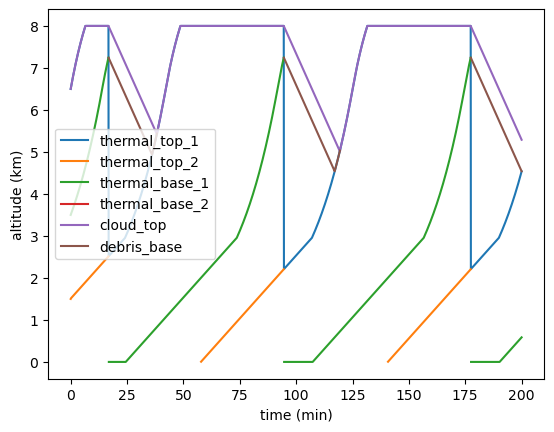

In [6]:
plt.plot(ncfile['time']/60, ncfile_envi['thermal_top_1'], label='thermal_top_1')
plt.plot(ncfile['time']/60, ncfile_envi['thermal_top_2'], label='thermal_top_2')
plt.plot(ncfile['time']/60, ncfile_envi['thermal_base_1'], label='thermal_base_1')
plt.plot(ncfile['time']/60, ncfile_envi['thermal_base_2'], label='thermal_base_2')
plt.plot(ncfile['time']/60, ncfile_envi['cloud_top'], label='cloud_top')
plt.plot(ncfile['time']/60, ncfile_envi['debris_base'], label='debris_base')

plt.ylabel("altitude (km)")
plt.xlabel("time (min)")
plt.legend()

Text(0, 0.5, 'altitude')

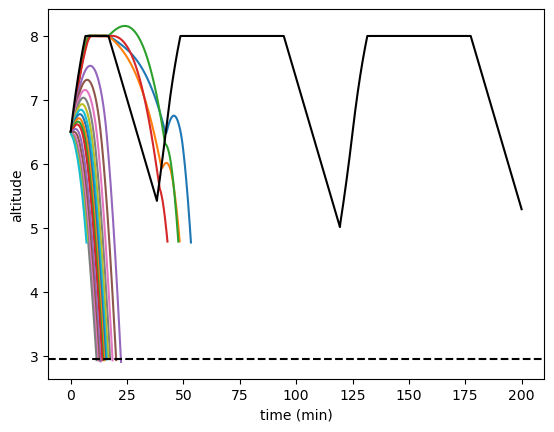

In [7]:
for s in range(ncfile_ice.sizes['particle']):
    p0_ice = ncfile_ice.isel(particle=s)
    #plt.plot(ncfile_v3_1['time'],p0_ice['altitude'])
    #plt.plot(p0_ice['diameter']*1000, p0_ice['altitude'])
    #plt.plot(ncfile['time']/60, p0_ice['diameter']*1000)
    #plt.plot(ncfile['time']/60, p0_ice['surface_temperature'])
    plt.plot(ncfile['time']/60, p0_ice['altitude']/1000)

#plt.plot(ncfile['time']/60, ncfile_envi['thermal_top_1'], label='thermal_top_1')
#plt.plot(ncfile['time']/60, ncfile_envi['thermal_top_2'], label='thermal_top_2')
#plt.plot(ncfile['time']/60, ncfile_envi['thermal_base_1'], label='thermal_base_1')
#plt.plot(ncfile['time']/60, ncfile_envi['thermal_base_2'], label='thermal_base_2')
plt.plot(ncfile['time']/60, ncfile_envi['cloud_top'],color='black', label='cloud_top')
#plt.plot(ncfile['time']/60, ncfile_envi['debris_base'], label='debris_base')

zbase = ptz(namelist['pbase']) # height of cloud base (m)
plt.axhline(y=zbase/1000, color='black', linestyle='--', label='cloud_base')

plt.xlabel("time (min)")
plt.ylabel("altitude")

In [16]:
non_nan_surface = p0_ice['surface_temperature'].values[~np.isnan(p0_ice['surface_temperature'].values)]
non_nan_surface

array([265.8365 , 265.8365 , 263.80853, 263.79752, 263.72293, 263.65024,
       263.57895, 263.57056, 263.50137, 263.43304, 263.36533, 263.29816,
       263.23145, 263.16513, 263.09915, 263.03348, 262.96805, 262.90283,
       262.83783, 262.773  , 262.64548, 262.5809 , 262.5596 , 262.49454,
       262.42963, 262.3648 , 262.30008, 262.23544, 262.17087, 262.0424 ,
       261.97794, 261.91345, 261.84924, 261.78506, 261.7209 , 261.65677,
       261.59265, 261.52856, 261.39987, 261.33575, 261.2716 , 261.20746,
       261.14334, 261.07922, 261.0151 , 260.95096, 260.88684, 260.8227 ,
       260.75854, 260.6289 , 260.5629 , 260.49683, 260.43073, 260.3646 ,
       260.29843, 260.2322 , 260.166  , 260.0997 , 260.0334 , 259.96704,
       259.90063, 259.8342 , 259.76773, 259.7012 , 259.56787, 259.5012 ,
       259.43445, 259.36765, 259.30078, 259.23386, 259.1669 , 259.09988,
       259.0328 , 258.96567, 258.89847, 258.83124, 258.76392, 258.69653,
       258.62912, 258.5616 , 258.49408, 258.42645, 

In [6]:
ncfile_ice

<xarray.Dataset> Size: 519kB
Dimensions:              (particle: 20, time: 721)
Dimensions without coordinates: particle, time
Data variables:
    diameter             (particle, time) float32 58kB ...
    density              (particle, time) float32 58kB ...
    mass                 (particle, time) float32 58kB ...
    surface_temperature  (particle, time) float32 58kB ...
    terminal_velocity    (particle, time) float32 58kB ...
    altitude             (particle, time) float32 58kB ...
    horizontal_position  (particle, time) float32 58kB ...
    horizontal_wind      (particle, time) float32 58kB ...
    concentration        (particle, time) float32 58kB ...

Text(0.5, 0, 'time (m)')

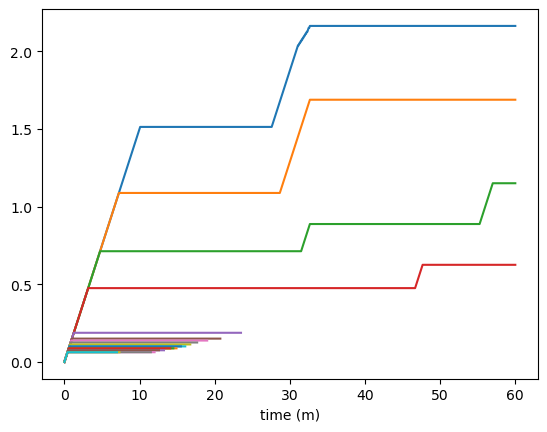

In [22]:
for s in range(ncfile_ice.sizes['particle']):
    p0_ice = ncfile_ice.isel(particle=s)
    #plt.plot(ncfile_v3_1['time'],p0_ice['altitude'])
    #plt.plot(p0_ice['diameter']*1000, p0_ice['altitude'])
    plt.plot(ncfile['time']/60, p0_ice['horizontal_position'])
    #plt.plot(p0_ice['diameter']*1000, p0_ice['altitude'])

plt.xlabel("time (m)")
#plt.ylabel("altitude (m)")


Text(0.5, 0, 'time (m)')

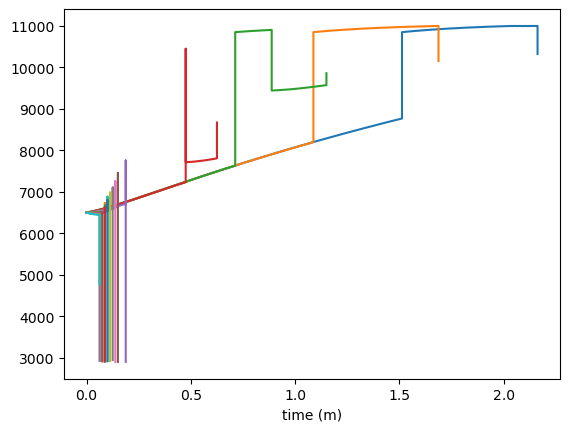

In [ ]:
for s in range(ncfile_ice.sizes['particle']):
    p0_ice = ncfile_ice.isel(particle=s)
    #plt.plot(ncfile_v3_1['time'],p0_ice['altitude'])
    #plt.plot(p0_ice['diameter']*1000, p0_ice['altitude'])
    plt.plot(p0_ice['horizontal_position'], p0_ice['altitude'])
    #plt.plot(p0_ice['diameter']*1000, p0_ice['altitude'])

plt.xlabel("time (m)")

# umax is 2.5 m/s?

In [ ]:
p0_ice

In [24]:
namelist['GENCTOP']

10.5